In [1]:
import pandas as pd 
import random 
from datetime import datetime, timedelta
from pathlib import Path
print("CareFlow project started successfully")

CareFlow project started successfully


In [2]:
import pandas as pd
import random
from datetime import datetime, timedelta
from pathlib import Path

random.seed(42)

events = []
start_date = datetime(2026, 10, 1, 8, 0)

for i in range(1, 201):
    patient_id = f"P{i:03d}"
    current_time = start_date + timedelta(
        minutes=random.randint(0, 480)
    )

    journey = [
        ("Registration", random.randint(3, 8)),
        ("Triage", random.randint(5, 15))
    ]

    if random.random() < 0.60:
        journey.append(("X-Ray", random.randint(10, 25)))

        if random.random() < 0.40:
            journey.append(("Triage", random.randint(5, 15)))

    journey.extend([
        ("Doctor Consultation", random.randint(10, 30)),
        ("Discharge", random.randint(2, 8))
    ])

    for activity, duration in journey:
        events.append({
            "Case_ID": patient_id,
            "Activity_Name": activity,
            "Timestamp": current_time
        })
        current_time += timedelta(minutes=duration)

df = pd.DataFrame(events)
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df = df.sort_values(
    ["Case_ID", "Timestamp"]
).reset_index(drop=True)

print("Dataset generated successfully!")
print("Total patients:", df["Case_ID"].nunique())
print("Total events:", len(df))

display(df.head(10))

Dataset generated successfully!
Total patients: 200
Total events: 959


,Case_ID,Activity_Name,Timestamp
0,P001,Registration,2026-10-01 13:27:00
1,P001,Triage,2026-10-01 13:30:00
2,P001,Doctor Consultation,2026-10-01 13:35:00
3,P001,Discharge,2026-10-01 13:52:00
4,P002,Registration,2026-10-01 09:11:00
5,P002,Triage,2026-10-01 09:19:00
6,P002,Doctor Consultation,2026-10-01 09:25:00
7,P002,Discharge,2026-10-01 09:52:00
8,P003,Registration,2026-10-01 13:02:00
9,P003,Triage,2026-10-01 13:08:00


In [3]:
print(df.shape)
print(df.head())
print(df.columns)

(959, 3)
  Case_ID        Activity_Name           Timestamp
0    P001         Registration 2026-10-01 13:27:00
1    P001               Triage 2026-10-01 13:30:00
2    P001  Doctor Consultation 2026-10-01 13:35:00
3    P001            Discharge 2026-10-01 13:52:00
4    P002         Registration 2026-10-01 09:11:00
Index(['Case_ID', 'Activity_Name', 'Timestamp'], dtype='object')


In [4]:
from pathlib import Path

output_folder = Path("data/raw")
output_folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv("data/raw/hospital_event_logs.csv")
print("Dataset saved successfully!")

Dataset saved successfully!


In [5]:
import pandas as pd

df = pd.read_csv("data/raw/hospital_event_logs.csv")
print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.isnull().sum())

  Case_ID        Activity_Name            Timestamp
0    P001         Registration  2026-10-01 13:27:00
1    P001               Triage  2026-10-01 13:30:00
2    P001  Doctor Consultation  2026-10-01 13:35:00
3    P001            Discharge  2026-10-01 13:52:00
4    P002         Registration  2026-10-01 09:11:00
Dataset shape: (959, 3)
Columns: ['Case_ID', 'Activity_Name', 'Timestamp']
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64


In [6]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)

Dataset shape: (959, 3)

Column names:
['Case_ID', 'Activity_Name', 'Timestamp']

Missing values:
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64

Duplicate rows: 0

Data types:
Case_ID          object
Activity_Name    object
Timestamp        object
dtype: object


In [7]:
# Make a copy of the original dataset
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.dropna(how="all")
print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

Original rows: 959
Rows after cleaning: 959
Duplicate rows removed: 0

Missing values after cleaning:
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64


In [8]:
# Display the column names
print(df_clean.columns.tolist())

['Case_ID', 'Activity_Name', 'Timestamp']


In [9]:
# Convert Timestamp column to datetime format
df_clean["Timestamp"] = pd.to_datetime(
    df_clean["Timestamp"], errors="coerce"
)

print(df_clean[["Timestamp"]].head())
print("Invalid timestamps:", df_clean["Timestamp"].isna().sum())
print("\nData types:")
print(df_clean.dtypes)

            Timestamp
0 2026-10-01 13:27:00
1 2026-10-01 13:30:00
2 2026-10-01 13:35:00
3 2026-10-01 13:52:00
4 2026-10-01 09:11:00
Invalid timestamps: 0

Data types:
Case_ID                  object
Activity_Name            object
Timestamp        datetime64[ns]
dtype: object


In [10]:
# Sort records by patient ID and timestamp
df_clean = df_clean.sort_values(
    by=["Case_ID", "Timestamp"]
).reset_index(drop=True)

print(df_clean.head(10))

  Case_ID        Activity_Name           Timestamp
0    P001         Registration 2026-10-01 13:27:00
1    P001               Triage 2026-10-01 13:30:00
2    P001  Doctor Consultation 2026-10-01 13:35:00
3    P001            Discharge 2026-10-01 13:52:00
4    P002         Registration 2026-10-01 09:11:00
5    P002               Triage 2026-10-01 09:19:00
6    P002  Doctor Consultation 2026-10-01 09:25:00
7    P002            Discharge 2026-10-01 09:52:00
8    P003         Registration 2026-10-01 13:02:00
9    P003               Triage 2026-10-01 13:08:00


In [11]:
# Sort activities by patient and time
df_clean = df_clean.sort_values(
    by=["Case_ID", "Timestamp"]
).reset_index(drop=True)

# Calculate time difference between activities for each patient
df_clean["Time_Taken_Minutes"] = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

print(df_clean[
    ["Case_ID", "Activity_Name", "Timestamp", "Time_Taken_Minutes"]
].head(12))

   Case_ID        Activity_Name           Timestamp  Time_Taken_Minutes
0     P001         Registration 2026-10-01 13:27:00                 NaN
1     P001               Triage 2026-10-01 13:30:00                 3.0
2     P001  Doctor Consultation 2026-10-01 13:35:00                 5.0
3     P001            Discharge 2026-10-01 13:52:00                17.0
4     P002         Registration 2026-10-01 09:11:00                 NaN
5     P002               Triage 2026-10-01 09:19:00                 8.0
6     P002  Doctor Consultation 2026-10-01 09:25:00                 6.0
7     P002            Discharge 2026-10-01 09:52:00                27.0
8     P003         Registration 2026-10-01 13:02:00                 NaN
9     P003               Triage 2026-10-01 13:08:00                 6.0
10    P003                X-Ray 2026-10-01 13:13:00                 5.0
11    P003               Triage 2026-10-01 13:29:00                16.0


In [12]:
# Calculate average time between activities
average_time = df_clean.groupby(
    "Activity_Name"
)["Time_Taken_Minutes"].mean()

print("Average time by activity:")
print(average_time.round(2))

Average time by activity:
Activity_Name
Discharge              20.03
Doctor Consultation    12.96
Registration             NaN
Triage                  7.99
X-Ray                   9.96
Name: Time_Taken_Minutes, dtype: float64


In [13]:
# Calculate average time between activities
transition_times = df_clean.groupby(
    "Activity_Name"
)["Time_Taken_Minutes"].mean()

print("Average time since the previous activity:")
print(transition_times.round(2))

Average time since the previous activity:
Activity_Name
Discharge              20.03
Doctor Consultation    12.96
Registration             NaN
Triage                  7.99
X-Ray                   9.96
Name: Time_Taken_Minutes, dtype: float64


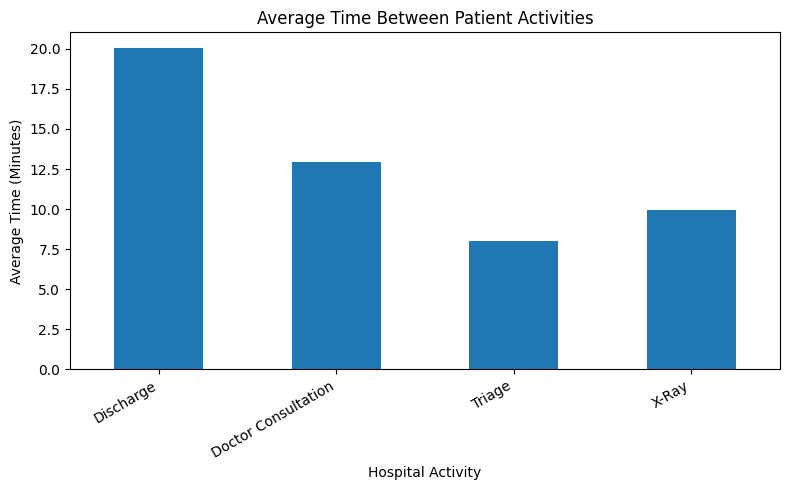

In [14]:
import matplotlib.pyplot as plt

transition_times = transition_times.dropna()

transition_times.plot(kind="bar", figsize=(8, 5))

plt.title("Average Time Between Patient Activities")
plt.xlabel("Hospital Activity")
plt.ylabel("Average Time (Minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Hospital Activity Counts:
Activity_Name
Triage                 246
Registration           200
Doctor Consultation    200
Discharge              200
X-Ray                  113
Name: count, dtype: int64


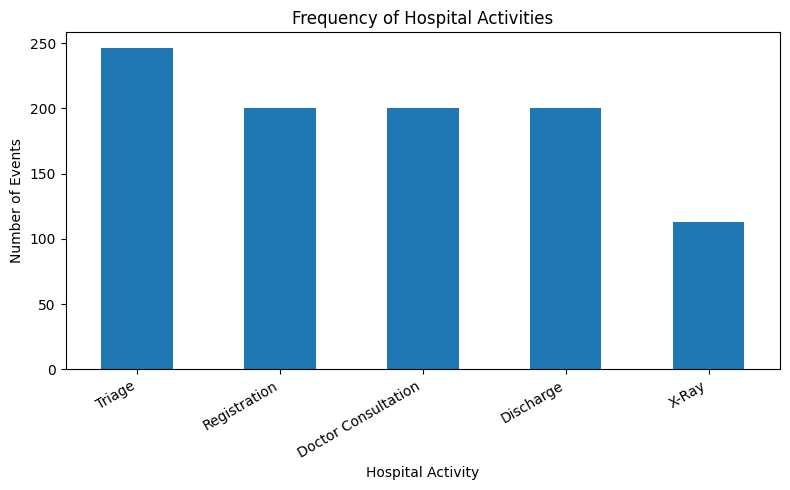

In [15]:
import matplotlib.pyplot as plt
activity_counts = df_clean["Activity_Name"].value_counts()
print("Hospital Activity Counts:")
print(activity_counts)
activity_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Frequency of Hospital Activities")
plt.xlabel("Hospital Activity")
plt.ylabel("Number of Events")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Average Time Gap by Activity (minutes):
Activity_Name
Discharge              20.03
Doctor Consultation    12.96
Triage                  7.99
X-Ray                   9.96
Name: Time_Taken_Minutes, dtype: float64


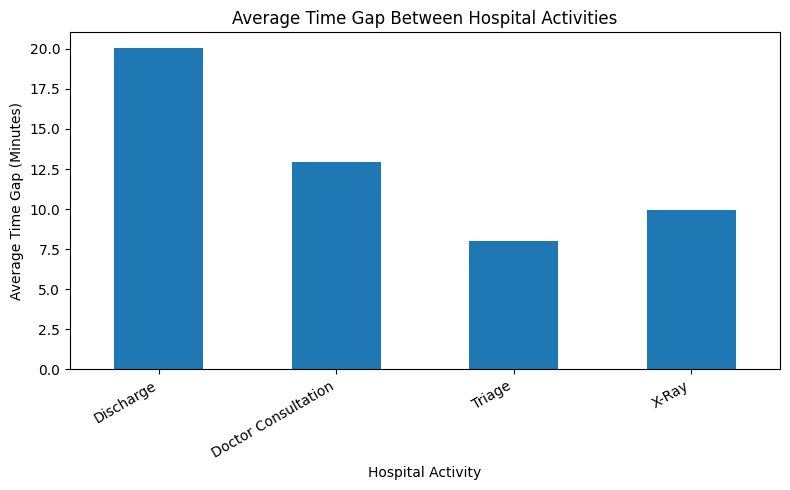

In [16]:
import matplotlib.pyplot as plt
df_clean = df_clean.sort_values(["Case_ID", "Timestamp"])
df_clean["Time_Taken_Minutes"] = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

waiting_time = (
    df_clean.groupby("Activity_Name")["Time_Taken_Minutes"]
    .mean()
    .dropna()
)

print("Average Time Gap by Activity (minutes):")
print(waiting_time.round(2))

# Create graph
waiting_time.plot(kind="bar", figsize=(8, 5))

plt.title("Average Time Gap Between Hospital Activities")
plt.xlabel("Hospital Activity")
plt.ylabel("Average Time Gap (Minutes)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "graph2_patient_waiting_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Top 5 Most Common Patient Pathways:
Activity_Name
Registration -> Triage -> Doctor Consultation -> Discharge                       87
Registration -> Triage -> X-Ray -> Doctor Consultation -> Discharge              67
Registration -> Triage -> X-Ray -> Triage -> Doctor Consultation -> Discharge    46
Name: count, dtype: int64


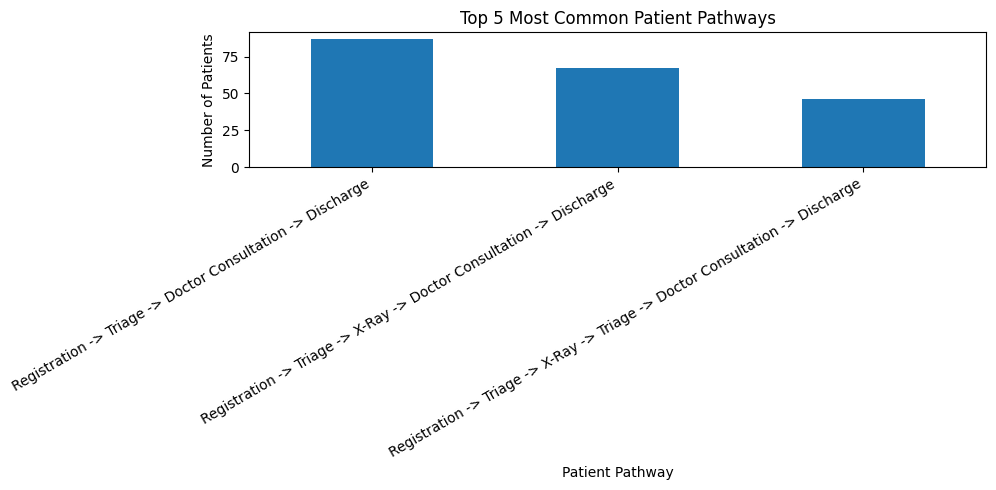

In [17]:
import matplotlib.pyplot as plt
df_clean = df_clean.sort_values(["Case_ID", "Timestamp"])
patient_paths = (
    df_clean.groupby("Case_ID")["Activity_Name"]
    .agg(" -> ".join)
)

path_counts = patient_paths.value_counts().head(5)
print("Top 5 Most Common Patient Pathways:")
print(path_counts)

# Plot the graph
path_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Top 5 Most Common Patient Pathways")
plt.xlabel("Patient Pathway")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "graph4_patient_pathways.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Patient Journey Duration (minutes):
Case_ID
P001    25.0
P002    41.0
P003    51.0
P004    46.0
P005    26.0
P006    52.0
P007    42.0
P008    76.0
P009    58.0
P010    55.0
Name: Timestamp, dtype: float64


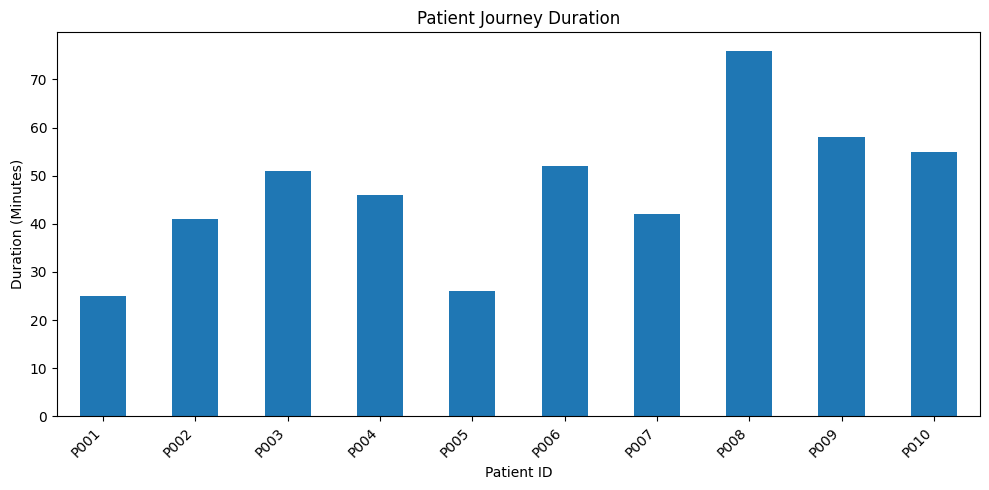

In [18]:
import matplotlib.pyplot as plt
patient_duration = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .agg(lambda x: (x.max() - x.min()).total_seconds() / 60)
)
print("Patient Journey Duration (minutes):")
print(patient_duration.head(10))

# Plot the first 10 patients
patient_duration.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Patient Journey Duration")
plt.xlabel("Patient ID")
plt.ylabel("Duration (Minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(
    "graph5_patient_journey_duration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [19]:
# Patient Activity Transition Analysis
df_clean = df_clean.sort_values(["Case_ID", "Timestamp"])
df_clean["Next_Activity"] = (
    df_clean.groupby("Case_ID")["Activity_Name"].shift(-1)
)
transitions = df_clean.dropna(subset=["Next_Activity"]).copy()
# Count transitions between activities
transitions["Activity_Transition"] = (
    transitions["Activity_Name"]
    + " -> "
    + transitions["Next_Activity"]
)
transition_counts = transitions["Activity_Transition"].value_counts()
print("Most Common Activity Transitions:")
print(transition_counts.head(10))


Most Common Activity Transitions:
Activity_Transition
Registration -> Triage              200
Doctor Consultation -> Discharge    200
Triage -> Doctor Consultation       133
Triage -> X-Ray                     113
X-Ray -> Doctor Consultation         67
X-Ray -> Triage                      46
Name: count, dtype: int64


Top 10 Patient Activity Transitions:
Activity_Transition
Registration -> Triage              200
Doctor Consultation -> Discharge    200
Triage -> Doctor Consultation       133
Triage -> X-Ray                     113
X-Ray -> Doctor Consultation         67
X-Ray -> Triage                      46
Name: count, dtype: int64


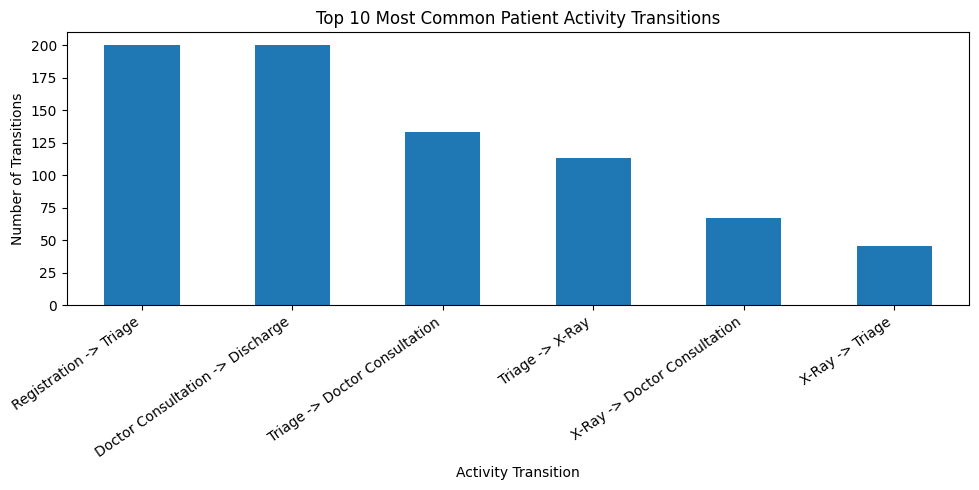

In [20]:
import matplotlib.pyplot as plt
# Count the most common transitions
transition_counts = (
    transitions["Activity_Transition"]
    .value_counts()
    .head(10)
)
print("Top 10 Patient Activity Transitions:")
print(transition_counts)
transition_counts.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Most Common Patient Activity Transitions")
plt.xlabel("Activity Transition")
plt.ylabel("Number of Transitions")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    "graph6_activity_transitions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [21]:

# Data Quality Report
print("===== DATA QUALITY REPORT =====")
# Total rows and columns
print("\nDataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
# Missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())
# Duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())
# Data types
print("\nColumn Data Types:")
print(df.dtypes)
# Missing timestamps after conversion
print("\nInvalid Timestamps:")
print(df_clean["Timestamp"].isnull().sum())
print("\nData quality report completed.")


===== DATA QUALITY REPORT =====

Dataset Shape:
Rows: 959
Columns: 3

Missing Values:
Case_ID          0
Activity_Name    0
Timestamp        0
dtype: int64

Duplicate Rows:
0

Column Data Types:
Case_ID          object
Activity_Name    object
Timestamp        object
dtype: object

Invalid Timestamps:
0

Data quality report completed.


In [22]:
# Step 2: Patient Journey Summary
patient_duration = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .agg(lambda x: (x.max() - x.min()).total_seconds() / 60)
)
print("===== PATIENT JOURNEY SUMMARY =====")
print("Total patients:", df_clean["Case_ID"].nunique())
print("Average journey duration (minutes):",
      round(patient_duration.mean(), 2))
print("Shortest journey (minutes):",
      round(patient_duration.min(), 2))
print("Longest journey (minutes):",
      round(patient_duration.max(), 2))


===== PATIENT JOURNEY SUMMARY =====
Total patients: 200
Average journey duration (minutes): 48.44
Shortest journey (minutes): 21.0
Longest journey (minutes): 79.0


In [23]:
# Hospital Bottleneck Analysis
df_clean = df_clean.sort_values(["Case_ID", "Timestamp"])
df_clean["Time_Taken_Minutes"] = (
    df_clean.groupby("Case_ID")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)
bottleneck_analysis = (
    df_clean.groupby("Activity_Name")["Time_Taken_Minutes"]
    .agg(["mean", "median", "max", "count"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("===== HOSPITAL BOTTLENECK ANALYSIS =====")
print(bottleneck_analysis)


===== HOSPITAL BOTTLENECK ANALYSIS =====
                      mean  median   max  count
Activity_Name                                  
Discharge            20.03    20.0  30.0    200
Doctor Consultation  12.96    12.0  25.0    200
X-Ray                 9.96    10.0  15.0    113
Triage                7.99     7.0  25.0    246
Registration           NaN     NaN   NaN      0


In [24]:
%pip install pm4py

PermissionError: [WinError 5] Access is denied

In [25]:
import pm4py
import pandas as pd

print("PM4Py version:", pm4py.__version__)
print("PM4Py imported successfully!")




  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




PM4Py version: 2.7.23.11
PM4Py imported successfully!


In [26]:
import pm4py
import pandas as pd
event_log = df_clean[
    ["Case_ID", "Activity_Name", "Timestamp"]
].copy()
event_log = event_log.rename(columns={
    "Case_ID": "case:concept:name",
    "Activity_Name": "concept:name",
    "Timestamp": "time:timestamp"
})
event_log = event_log.sort_values(
    ["case:concept:name", "time:timestamp"]
)
event_log = pm4py.format_dataframe(
    event_log,
    case_id="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp"
)
print("===== PROCESS MINING DATA SUMMARY =====")
print("Total patients:", event_log["case:concept:name"].nunique())
print("Total events:", len(event_log))
print("Unique activities:", event_log["concept:name"].nunique())

print("\nActivity Frequency:")
print(event_log["concept:name"].value_counts())


===== PROCESS MINING DATA SUMMARY =====
Total patients: 200
Total events: 959
Unique activities: 5

Activity Frequency:
concept:name
Triage                 246
Registration           200
Doctor Consultation    200
Discharge              200
X-Ray                  113
Name: count, dtype: Int64


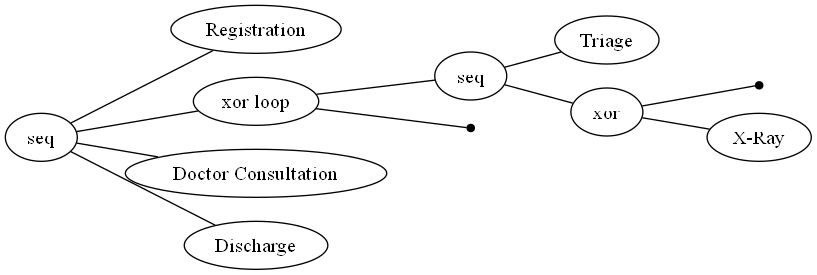

In [27]:
# Discover the hospital process model
process_tree = pm4py.discover_process_tree_inductive(event_log)

# Display the process model
pm4py.view_process_tree(process_tree)


In [28]:
print("===== PATIENT ACTIVITY SEQUENCES =====")

patient_paths = (
    event_log.sort_values(["case:concept:name", "time:timestamp"])
    .groupby("case:concept:name")["concept:name"]
    .agg(" -> ".join)
)

display(patient_paths.head(20).to_frame(name="Activity Sequence"))


===== PATIENT ACTIVITY SEQUENCES =====


,Activity Sequence
case:concept:name,
P001,Registration -> Triage -> Doctor Consultation ...
P002,Registration -> Triage -> Doctor Consultation ...
P003,Registration -> Triage -> X-Ray -> Triage -> D...
P004,Registration -> Triage -> Doctor Consultation ...
P005,Registration -> Triage -> Doctor Consultation ...
P006,Registration -> Triage -> X-Ray -> Triage -> D...
P007,Registration -> Triage -> Doctor Consultation ...
P008,Registration -> Triage -> X-Ray -> Triage -> D...
P009,Registration -> Triage -> X-Ray -> Triage -> D...


===== MOST COMMON PATIENT PATHWAYS =====


,Patient Count
concept:name,
Registration -> Triage -> Doctor Consultation -> Discharge,87
Registration -> Triage -> X-Ray -> Doctor Consultation -> Discharge,67
Registration -> Triage -> X-Ray -> Triage -> Doctor Consultation -> Discharge,46


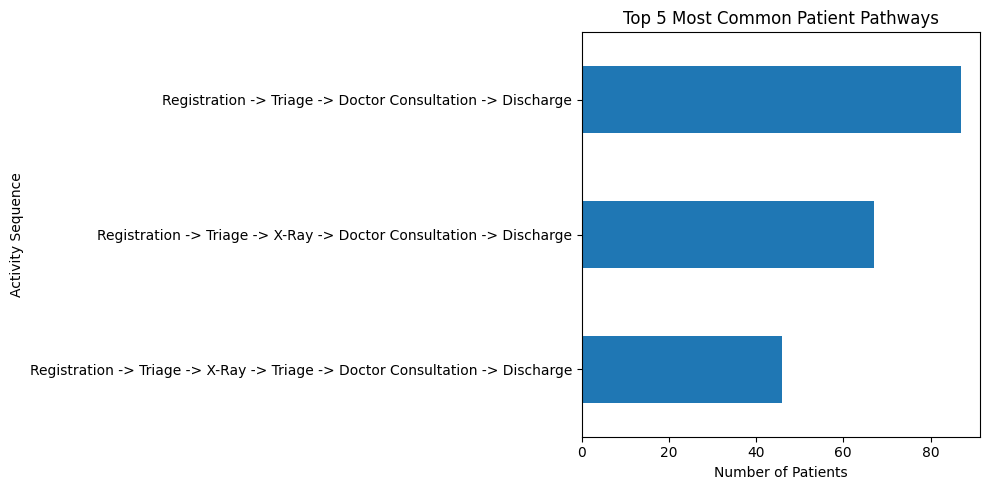

In [31]:
print("===== MOST COMMON PATIENT PATHWAYS =====")

path_counts = patient_paths.value_counts()
display(path_counts.head(10).to_frame(name="Patient Count"))

import matplotlib.pyplot as plt

path_counts.head(5).sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Top 5 Most Common Patient Pathways")
plt.xlabel("Number of Patients")
plt.ylabel("Activity Sequence")
plt.tight_layout()
plt.savefig("graph4_patient_pathways.png", dpi=300)
plt.show()


In [29]:
dfg, start_activities, end_activities = pm4py.discover_dfg(event_log)

print("===== HOSPITAL ACTIVITY FLOW =====")
print("Start activities:", start_activities)
print("End activities:", end_activities)

print("\nActivity transitions and frequencies:")

for (activity1, activity2), frequency in sorted(
    dfg.items(), key=lambda item: item[1], reverse=True
):
    print(f"{activity1} -> {activity2}: {frequency}")


===== HOSPITAL ACTIVITY FLOW =====
Start activities: {'Registration': 200}
End activities: {'Discharge': 200}

Activity transitions and frequencies:
Doctor Consultation -> Discharge: 200
Registration -> Triage: 200
Triage -> Doctor Consultation: 133
Triage -> X-Ray: 113
X-Ray -> Doctor Consultation: 67
X-Ray -> Triage: 46


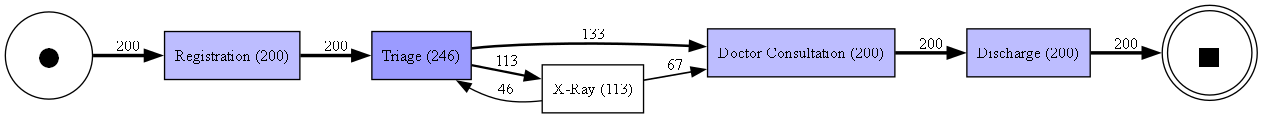

In [30]:
pm4py.view_dfg(dfg, start_activities, end_activities)
